In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import os
import sys
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move_special import *
import pygame

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [2]:
def create_graph_from_grid(grid):
    rows, cols = grid.shape
    G = nx.Graph()

    # Get all active nodes (where grid == 1)
    nodes = np.argwhere(grid == 1)
    G.add_nodes_from(map(tuple, nodes))  # Convert to tuple for hashability

    # Define the 8 possible moves
    directions = np.array([[-1, -1], [-1, 0], [-1, 1],
                           [0, -1],          [0, 1],
                           [1, -1],  [1, 0],  [1, 1]])

    # Compute valid neighbor coordinates with periodic boundaries
    for r, c in nodes:
        for dr, dc in directions:
            nr = (r + dr) % rows  # Wrap around row boundaries
            nc = (c + dc) % cols  # Wrap around column boundaries
            if grid[nr, nc] == 1:  # Only add edges if the neighbor is also 1
                G.add_edge((r, c), (nr, nc))

    return G
    
def get_largest_connected_component(G):
    try:
        largest_cc = max(nx.connected_components(G), key=len)
        return G.subgraph(largest_cc).copy()
    except ValueError: 
        return nx.Graph() 

In [3]:
n = 300
Lx = 32
Ly = 32
eta = 0.01
decay_rate = 0.015
beta = 4.5
delta = 0.3
n_special = 30
t_transient = 200
tmax = 1200
eta_special = 1
beta_special = 4.5
delta_special = 0.3

In [4]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [5]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [20]:
positions = np.zeros((len(beta_list), len(delta_list), n, 2))
pheromones = np.zeros((len(beta_list), len(delta_list), Lx, Ly))
max_counter = np.zeros((len(beta_list), len(delta_list), 1))
for beta in beta_list:
    for delta in delta_list:
        print(f"Testing with delta = {delta}, beta = {beta}")

        env = Ants_move_special(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                  beta, delta, tmax, n_special, t_transient) # in this case beta, delta are beta and delta also for special ants
        
        env.reset_objects()
        env.transient()
        
        for t in range(tmax-t_transient):
            env.update()
        
        final_positions = env.positions.copy()
        final_field = env.pheromones.copy()

        positions[beta_list.index(beta), delta_list.index(delta), :, :] = final_positions[:n]
        pheromones[beta_list.index(beta), delta_list.index(delta), :, :] = final_field
        # max_counter[beta_list.index(beta), delta_list.index(delta)] = env.best_choice_count.copy()

Testing with delta = 0.3, beta = 3.5
Testing with delta = 0.4, beta = 3.5
Testing with delta = 0.5, beta = 3.5
Testing with delta = 0.6, beta = 3.5
Testing with delta = 0.7, beta = 3.5
Testing with delta = 0.8, beta = 3.5
Testing with delta = 0.3, beta = 4.5
Testing with delta = 0.4, beta = 4.5
Testing with delta = 0.5, beta = 4.5
Testing with delta = 0.6, beta = 4.5
Testing with delta = 0.7, beta = 4.5
Testing with delta = 0.8, beta = 4.5
Testing with delta = 0.3, beta = 5.5
Testing with delta = 0.4, beta = 5.5
Testing with delta = 0.5, beta = 5.5
Testing with delta = 0.6, beta = 5.5
Testing with delta = 0.7, beta = 5.5
Testing with delta = 0.8, beta = 5.5
Testing with delta = 0.3, beta = 6.5
Testing with delta = 0.4, beta = 6.5
Testing with delta = 0.5, beta = 6.5
Testing with delta = 0.6, beta = 6.5
Testing with delta = 0.7, beta = 6.5
Testing with delta = 0.8, beta = 6.5
Testing with delta = 0.3, beta = 7.5
Testing with delta = 0.4, beta = 7.5
Testing with delta = 0.5, beta = 7.5
T

In [6]:
save = False
if save:
    np.savez_compressed(
    "simulation_results_300_30.npz",
    positions=positions,
    pheromones=pheromones,
    )

In [7]:
load = True
if load:
    data = np.load("simulation_results_300_30.npz")
    positions = data["positions"]
    pheromones = data["pheromones"]

In [ ]:
from matplotlib.gridspec import GridSpec

def plot_field(field, beta_list, delta_list, cmap='YlGnBu'):
    fig = plt.figure(figsize=(6,8))
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    # subplot della griglia
    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i,j] = fig.add_subplot(gs[i,j])
            ax[i,j].imshow(np.log(field[len(beta_list)-i-1,j][::-1]), cmap=cmap,
                            vmin=min(np.log(field).flatten()), vmax=max(np.log(field).flatten()))
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])
            if j == 0:
                ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)
            if i == len(beta_list)-1:
                ax[i,j].set_xlabel(f'{delta_list[j]}', fontsize=10)

    # asse globale che copre tutto il gridspec
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    ax_curve.plot(delta_list, [beta_crit(d, s0) for d in delta_list],
                color='red', linestyle='--', linewidth=2)
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
    #fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
    fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
    #fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
    # title('Final positions of the ants', fontsize=16)
    fig.text(0.5, 1.02, 'Final pheromone field (abm-ants and smart-agents)', fontsize=12, ha='center')

    plt.tight_layout()
    plt.show()

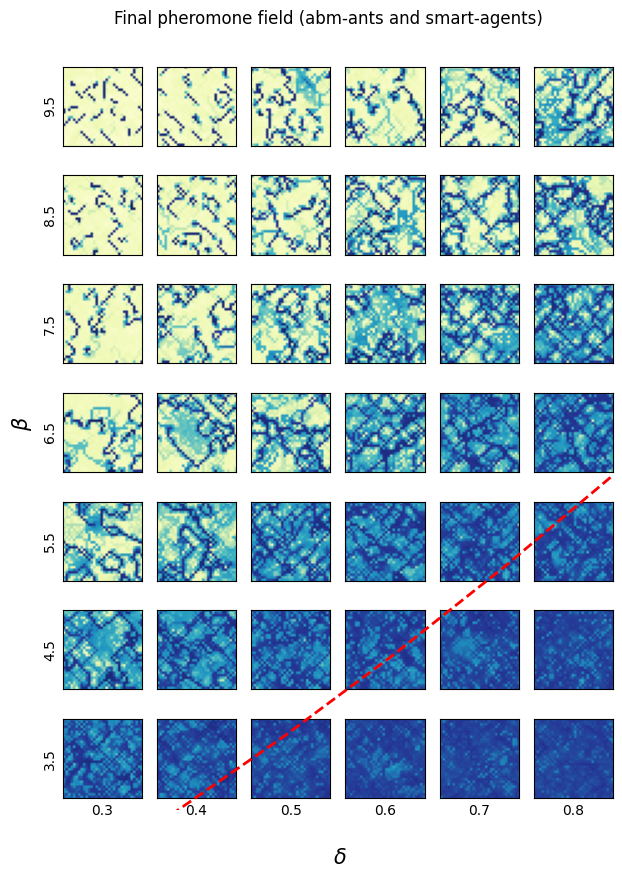

In [11]:
plot_field(pheromones, beta_list, delta_list)

In [ ]:
plot_field(pheromones, beta_list, delta_list)

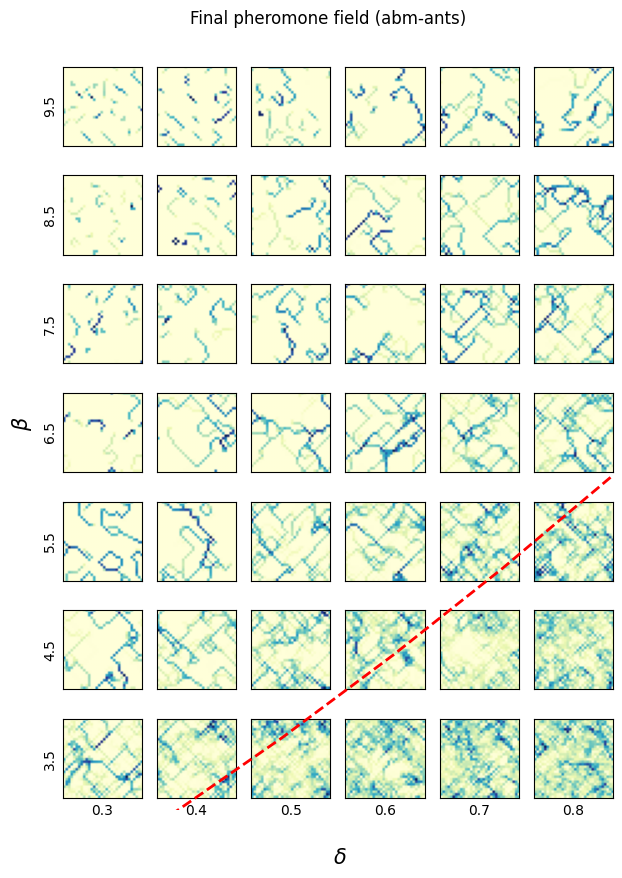

In [25]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(6,8))
gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

# subplot della griglia
ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
for i in range(len(beta_list)):
    for j in range(len(delta_list)):
        ax[i,j] = fig.add_subplot(gs[i,j])
        ax[i,j].imshow(pheromones[len(beta_list)-i-1,j][::-1], cmap='YlGnBu')
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])
        if j == 0:
            ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)
        if i == len(beta_list)-1:
            ax[i,j].set_xlabel(f'{delta_list[j]}', fontsize=10)

# asse globale che copre tutto il gridspec
ax_curve = fig.add_subplot(gs[:,:], frameon=False)
ax_curve.plot(delta_list, [beta_crit(d, s0) for d in delta_list],
              color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(min(delta_list), max(delta_list))
ax_curve.set_ylim(min(beta_list), max(beta_list))
ax_curve.set_xticks([])
ax_curve.set_yticks([])

fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
#fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
#fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
# title('Final positions of the ants', fontsize=16)
fig.text(0.5, 1.02, 'Final pheromone field (abm-ants)', fontsize=12, ha='center')

plt.tight_layout()
plt.savefig('pher_gridplot.png')
plt.show()

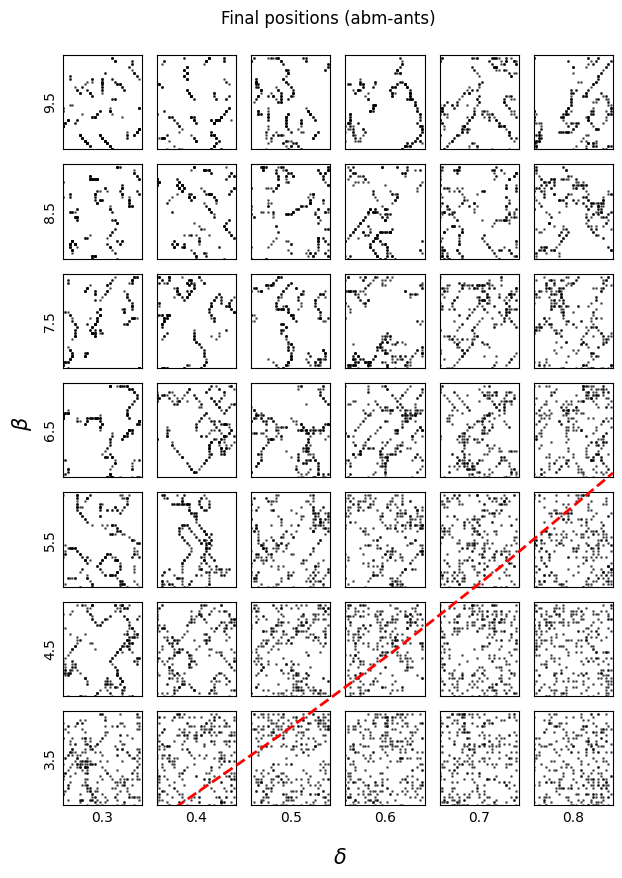

In [26]:
fig, ax = plt.subplots(len(beta_list), len(delta_list), figsize=(6,8))

for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):

        ax[i,j].scatter(positions[len(beta_list)-i-1,j,:,1],positions[len(beta_list)-i-1,j,:,0], s=1, c='black', alpha=0.5)
        ax[i,j].set_xlim(0,Lx)
        ax[i,j].set_ylim(0,Ly)
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])

        if j == 0:
            ax[i,j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)

        if i == len(beta_list) - 1:
            ax[i,j].set_xlabel(f'{delta}', fontsize=10)

# asse globale che copre tutto il gridspec
ax_curve = fig.add_subplot(gs[:,:], frameon=False)
ax_curve.plot(delta_list, [beta_crit(d, s0) for d in delta_list],
              color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(min(delta_list), max(delta_list))
ax_curve.set_ylim(min(beta_list), max(beta_list))
ax_curve.set_xticks([])
ax_curve.set_yticks([])

fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
#fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
#fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
# title('Final positions of the ants', fontsize=16)
fig.text(0.5, 1.02, 'Final positions (abm-ants)', fontsize=12, ha='center')

plt.tight_layout()
plt.savefig('ants_gridplot.png')
plt.show()

In [18]:
def order_parameter_d(pheromone, position):
    ns0 = np.mean(pheromone)
    plus_id = pheromone > ns0
    minus_id = pheromone <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    position = np.array(position, dtype=int)
    rho = np.bincount(np.array(position[:,0]*Ly + position[:,1]), minlength=Lx*Ly)
    rho = rho.reshape((Lx, Ly))
    mu_plus = np.sum(rho[plus_id])
    mu_minus = np.sum(rho[minus_id])

    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        local_op = (mu_plus - mu_minus)/(n+n_special)
        return local_op
    
order_parameters_d = np.zeros((len(beta_list), len(delta_list)))
for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):
        order_parameters_d[i,j] = order_parameter_d(pheromones[i,j], positions[i,j])

In [15]:
def order_parameter_p(pheromone):
    ns0 = np.mean(pheromone)
    plus_id = pheromone > ns0
    minus_id = pheromone <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)

    s_plus = np.sum(pheromone[plus_id])
    s_minus = np.sum(pheromone[minus_id])

    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        local_op = (s_plus - s_minus)/(s_plus + s_minus)
        return local_op
    
order_parameters_p = np.zeros((len(beta_list), len(delta_list)))
for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):
        order_parameters_p[i,j] = order_parameter_p(pheromones[i,j])

In [57]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize

def plot_order_parameter(op, beta_list, delta_list, cmap='summer', op_name='pheromone'):

    fig = plt.figure(figsize=(8,8), constrained_layout=True)
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    vmin, vmax = np.min(op), np.max(op)
    norm = Normalize(vmin=vmin, vmax=vmax)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)
    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i, j] = fig.add_subplot(gs[i, j])
            img = ax[i, j].imshow(
                np.ones((1, 1)) * op[len(beta_list)-i-1, j],
                cmap=cmap,
                norm=norm
            )
            ax[i, j].set_xticks([])
            ax[i, j].set_yticks([])

            if j == 0:
                ax[i, j].set_ylabel(f'{beta_list[len(beta_list)-i-1]}', fontsize=10)
            if i == len(beta_list)-1:
                ax[i, j].set_xlabel(f'{delta_list[j]}', fontsize=10)

    # Overlay curve axis
    ax_curve = fig.add_subplot(gs[:, :], frameon=False)
    ax_curve.plot(
        delta_list,
        [beta_crit(d, s0) for d in delta_list],
        color='red', linestyle='--', linewidth=2
    )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    # Shared colorbar
    cbar = fig.colorbar(img, ax=ax.ravel().tolist(), shrink=0.75, pad=0.1)

    # Global labels
    fig.text(-0.05, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
    fig.text(0.42, -0.03, r'$\delta$', fontsize=15, ha='center')
    fig.text(0.42, 1.02, f'{op_name} order parameter', fontsize=12, ha='center')

    plt.show()

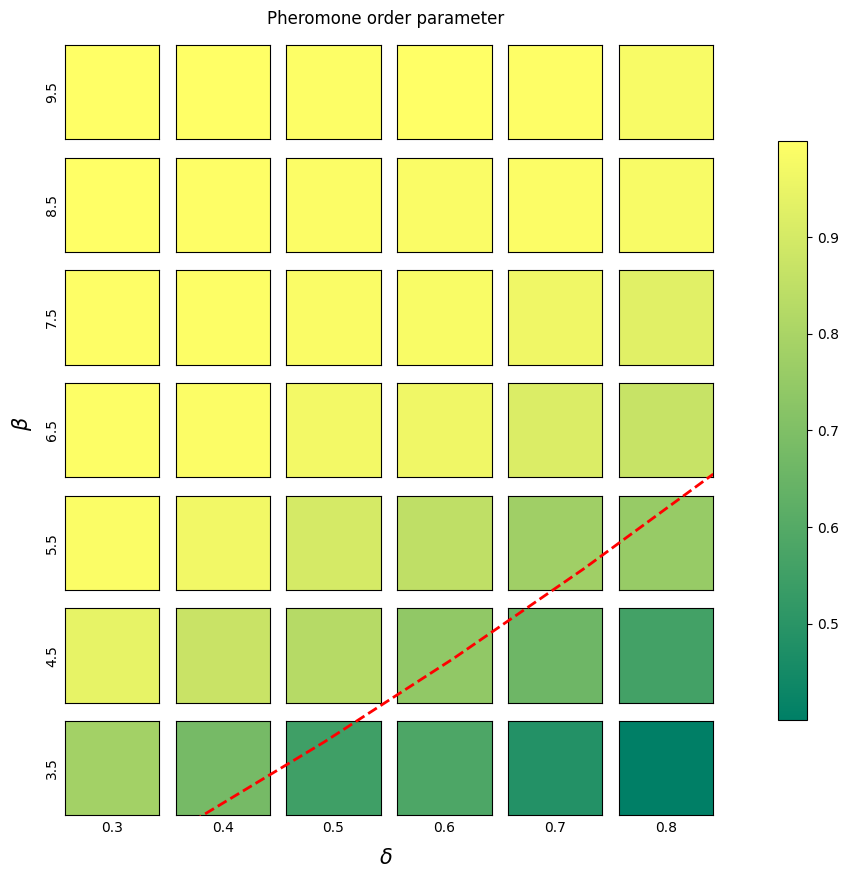

In [58]:
plot_order_parameter(order_parameters_p, beta_list, delta_list, cmap='summer', op_name='Pheromone')

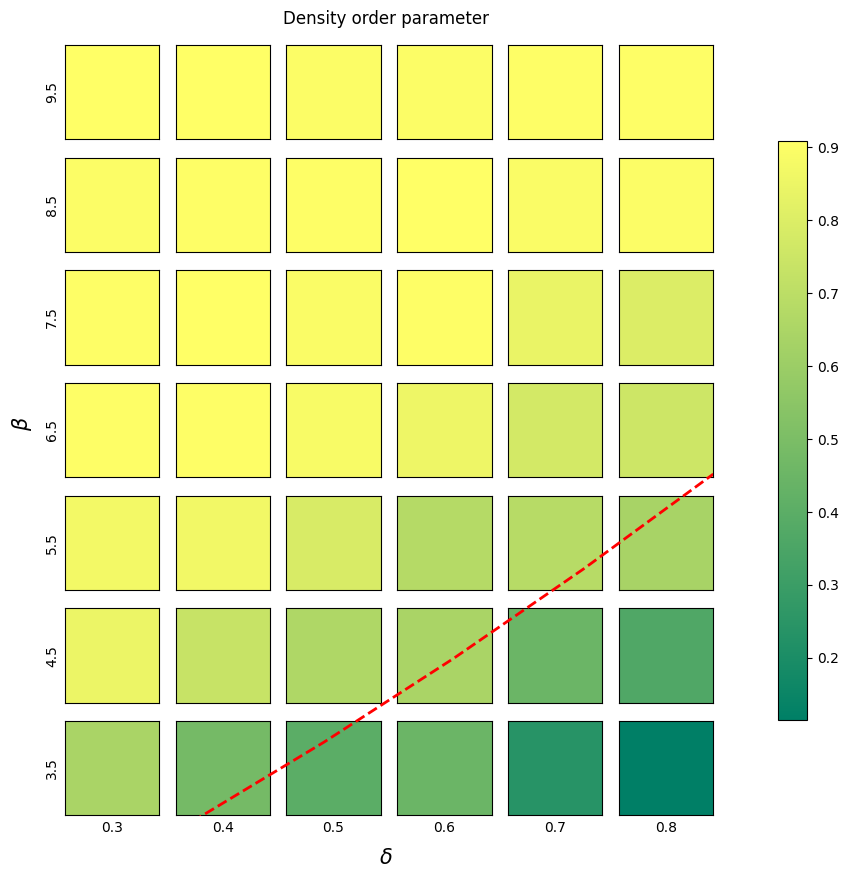

In [59]:
plot_order_parameter(order_parameters_d, beta_list, delta_list, cmap='summer', op_name='Density')